# 05 - A tour of SMAClite (StarCraft micromanagement)

**SMAClite** is a lightweight Python re-implementation of the StarCraft Multi-Agent Challenge (SMAC) - the standard benchmark for cooperative MARL -
without needing the StarCraft II game.

* Two armies fight on a small map. **Every unit of our army is one RL agent**; the enemy army is controlled by a simple built-in script
  (it attack-moves towards our starting point).
* Agents see only what is near them, choose from a small set of discrete actions, and the whole team receives **one shared reward**.

This notebook explores the environment: no learning yet, agents act randomly.

In [1]:
%matplotlib inline
import random
import matplotlib.pyplot as plt
from marl.smac_tools import *
from marl.render import show_video
plt.rcParams["figure.dpi"] = 90

## The maps
Each map is a fixed battle scenario. Same armies on both sides (e.g. `2s3z`) = symmetric; otherwise one side is stronger (e.g. `10m_vs_11m`).
`actions` = choices per agent, `obs` = numbers each agent observes, `state` = numbers in the global state used only during training.

In [2]:
print_table(map_overview())

map           agents  allies                             enemies                            actions  obs  state
10m_vs_11m    10      10 marine                          11 marine                          17       105  243  
27m_vs_30m    27      27 marine                          30 marine                          36       285  1170 
2c_vs_64zg    2       2 colossus                         64 zergling                        70       332  342  
2s3z          5       2 stalker + 3 zealot               2 stalker + 3 zealot               11       80   120  
2s_vs_1sc     2       2 stalker                          1 spine_crawler                    7        17   27   
3s5z          8       3 stalker + 5 zealot               3 stalker + 5 zealot               14       128  216  
3s5z_vs_3s6z  8       3 stalker + 5 zealot               3 stalker + 6 zealot               15       136  230  
3s_vs_5z      3       3 stalker                          5 zealot                           11       48 

## Map `2s3z`: 2 Stalkers + 3 Zealots on each side
* **Stalker** - ranged unit (range 6), fast, armoured; deals extra damage to armoured targets.
* **Zealot** - melee unit (has to touch its target), hits twice per attack.
* Both have a **shield** that is damaged before health.

In [3]:
env = make_smac("2s3z")
print_mdp(env)
print()
print_table(unit_stats(env))

map 2s3z: 5 agents ['stalker', 'stalker', 'zealot', 'zealot', 'zealot'] vs 5 scripted enemies ['stalker', 'stalker', 'zealot', 'zealot', 'zealot']
actions per agent: 11 | observation: 80 numbers | global state: 120 numbers
actions: 0=no-op (dead agents only), 1=stop, 2=move north, 3=move south, 4=move east, 5=move west, 6=attack enemy 0 (stalker), 7=attack enemy 1 (stalker), 8=attack enemy 2 (zealot), 9=attack enemy 3 (zealot), 10=attack enemy 4 (zealot)

unit     hp   shield  armor  damage  attacks  cooldown_s  attack_range  speed  role    bonus        
stalker  80   80      1      13      1        1.34        6             4.13   damage  +5 vs armored
zealot   100  50      1      8       2        0.86        0.1           3.15   damage               


## Time and episodes
* One environment step = **8 game ticks = 0.5 s** of game time. All agents act at the same time.
* The episode ends when one army is dead. SMAClite has **no time limit** - when training we stop episodes after 150 steps.

## Actions (discrete, one per agent per step)
| id | action |
|---|---|
| 0 | no-op - only for dead agents |
| 1 | stop |
| 2-5 | move north / south / east / west (2 distance units) |
| 6 + j | attack enemy *j* (a healer instead heals ally *j*) |

Not every action is allowed at every moment: an **availability mask** removes e.g. attacks on enemies that are dead or out of range (6), or moves into walls.
The agent must pick an available action.

In [4]:
obs, _ = env.reset(seed=0)
print("at the start, agent 0 can:", available(env, 0))
pick = random_policy(0)
t = 0
while not has_attack(env, 0):             # random moves until an enemy is within agent 0's range
    obs, r, done, _, _ = env.step(pick(env, obs))
    t += 1
print(f"{t} steps later, agent 0 can:", available(env, 0))

at the start, agent 0 can: ['stop', 'move north', 'move south', 'move east', 'move west']
24 steps later, agent 0 can: ['stop', 'move north', 'move south', 'move east', 'move west', 'attack enemy 2 (zealot)', 'attack enemy 3 (zealot)']


## What one agent observes
Each agent sees only units within **sight range 9** (its weapon reaches only 6). All positions are **relative to itself** and divided by the sight range.
Units it cannot see are all zeros. Below: the non-zero features of agent 0's observation right now (`decode(..., nonzero_only=False)` shows all of them).

In [5]:
print(f"agent 0 observes {env.obs_size} numbers; non-zero right now:")
print_table(decode(obs_feature_names(env, agent=0), obs[0]))

agent 0 observes 80 numbers; non-zero right now:
feature                        value 
can move north                 1.0   
can move south                 1.0   
can move east                  1.0   
can move west                  1.0   
enemy 0 (stalker): distance    0.952 
enemy 0 (stalker): dx          0.948 
enemy 0 (stalker): dy          0.092 
enemy 0 (stalker): health      1.0   
enemy 0 (stalker): shield      0.775 
enemy 0 (stalker): is stalker  1.0   
enemy 2 (zealot): attackable   1.0   
enemy 2 (zealot): distance     0.633 
enemy 2 (zealot): dx           0.576 
enemy 2 (zealot): dy           0.263 
enemy 2 (zealot): health       1.0   
enemy 2 (zealot): shield       0.36  
enemy 2 (zealot): is zealot    1.0   
enemy 3 (zealot): attackable   1.0   
enemy 3 (zealot): distance     0.588 
enemy 3 (zealot): dx           0.57  
enemy 3 (zealot): dy           0.146 
enemy 3 (zealot): health       1.0   
enemy 3 (zealot): shield       0.36  
enemy 3 (zealot): is zealot    1.0   
e

## The global state (only for centralised training)
The state has **every unit on the map** with **absolute** positions (relative to the map centre), health, weapon cooldown, shields, unit types,
plus **the last action of every agent**. Agents never see it when acting; centralised critics/mixers use it during training.

In [6]:
state = env.get_state()
rows = decode(state_feature_names(env), state)
print(f"state: {env.state_size} numbers; first non-zero ones:")
print_table(rows[:25])

state: 120 numbers; first non-zero ones:
feature                        value 
ally 0 (stalker): health       1.0   
ally 0 (stalker): x            -0.379
ally 0 (stalker): y            -0.031
ally 0 (stalker): shield       1.0   
ally 0 (stalker): is stalker   1.0   
ally 2 (zealot): health        1.0   
ally 2 (zealot): x             -0.496
ally 2 (zealot): y             -0.11 
ally 2 (zealot): shield        1.0   
ally 2 (zealot): is zealot     1.0   
enemy 0 (stalker): health      1.0   
enemy 0 (stalker): x           -0.113
enemy 0 (stalker): y           -0.005
enemy 0 (stalker): shield      0.775 
enemy 0 (stalker): is stalker  1.0   
enemy 1 (stalker): health      1.0   
enemy 1 (stalker): x           -0.097
enemy 1 (stalker): y           0.031 
enemy 1 (stalker): shield      1.0   
enemy 1 (stalker): is stalker  1.0   
enemy 2 (zealot): health       1.0   
enemy 2 (zealot): x            -0.217
enemy 2 (zealot): y            0.043 
enemy 2 (zealot): shield       0.36  
enemy 2 (

## The reward
**One number per step, given to every agent:**

* damage dealt to enemies (health + shield, after armour)
* **+10** for every enemy killed
* **+200** for winning the battle
* taking damage is **not** punished

The total is scaled so that a perfect episode adds up to **20**. Below, a random episode: the reward split into its three parts,
both teams' health, and how much damage each of our agents actually dealt.

34 steps, won: False, return: 4.65 / 20


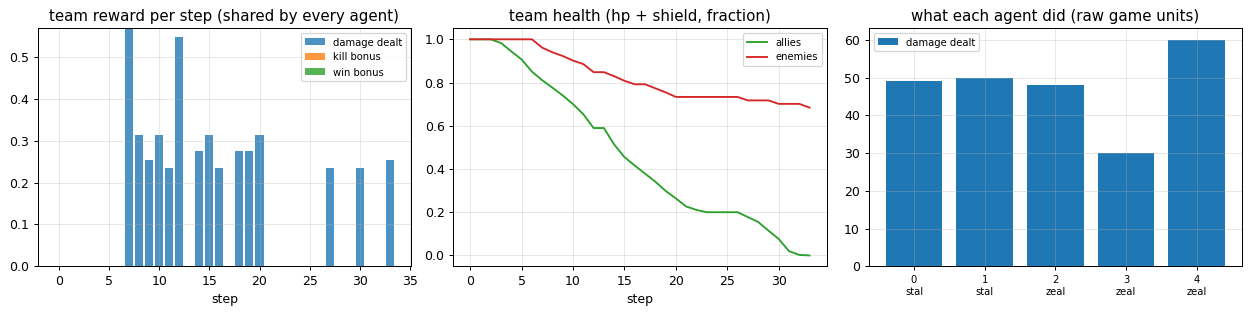

In [7]:
frames, records = rollout_smac(env, seed=1)
print(f"{len(records)} steps, won: {records[-1]['won']}, return: {sum(r['reward'] for r in records):.2f} / 20")
plot_episode(records, env)
plt.tight_layout()
show_video(frames, fps=6, width=720)

## Map `MMM`: Marines, Marauders and a Medivac
10 agents: 7 **Marines** (cheap, ranged), 2 **Marauders** (ranged, strong against armour) and 1 **Medivac** - a flying healer that **cannot attack**:
its actions are *heal ally j*.

In [8]:
mmm = make_smac("MMM")
print_mdp(mmm, agent=0)          # agent 0 is the Medivac: its target actions are heals
print()
print_table(unit_stats(mmm))

map MMM: 10 agents ['medivac', 'marine', 'marine', 'marine', 'marine', 'marine', 'marine', 'marine', 'marauder', 'marauder'] vs 10 scripted enemies ['medivac', 'marine', 'marine', 'marine', 'marine', 'marine', 'marine', 'marine', 'marauder', 'marauder']
actions per agent: 16 | observation: 160 numbers | global state: 290 numbers
actions: 0=no-op (dead agents only), 1=stop, 2=move north, 3=move south, 4=move east, 5=move west, 6=heal ally 0 (medivac), 7=heal ally 1 (marine), 8=heal ally 2 (marine), 9=heal ally 3 (marine), 10=heal ally 4 (marine), 11=heal ally 5 (marine), 12=heal ally 6 (marine), 13=heal ally 7 (marine), 14=heal ally 8 (marauder), 15=heal ally 9 (marauder)

unit      hp   shield  armor  damage  attacks  cooldown_s  attack_range  speed  role     bonus         
medivac   150  0       1      0       1        0           4             3.5    healing                
marine    45   0       0      6       1        0.61        5             3.15   damage                 
maraude

47 steps, won: False, return: 1.56 / 20
the Medivac healed 4 hp - and the reward contains no term for healing


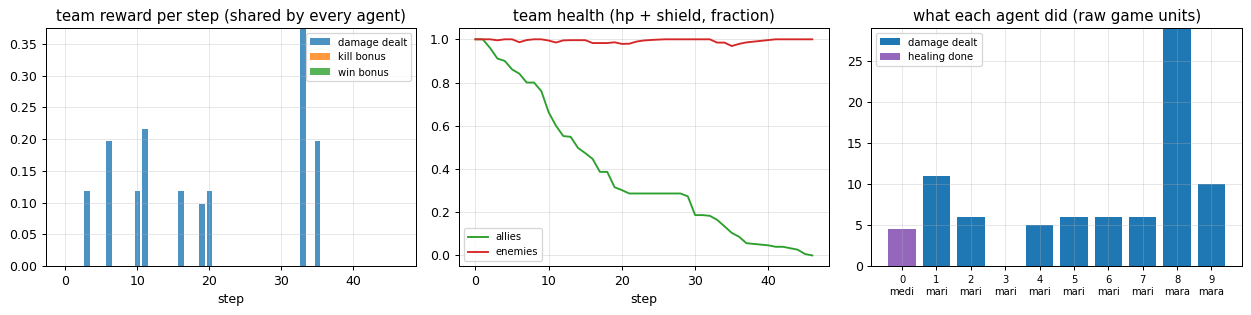

In [9]:
frames, records = rollout_smac(mmm, seed=0)
print(f"{len(records)} steps, won: {records[-1]['won']}, return: {sum(r['reward'] for r in records):.2f} / 20")
heal = sum(r['healing'][0] for r in records)
print(f"the Medivac healed {heal:.0f} hp - and the reward contains no term for healing")
plot_episode(records, mmm)
plt.tight_layout()
show_video(frames, fps=6, width=720)